# Produtos e categorias

Quais produtos, categorias e faixas de preço, peso e volume concentram avaliações ruins? Analisa pedidos entregues, avaliados e com um item.

In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)


In [2]:
from pathlib import Path

# Procura a raiz a partir da pasta atual; funciona também nas cópias em outputs/notebooks.
RAIZ_PROJETO = next(
    (pasta for pasta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (pasta / 'executar_pipeline.py').is_file() and (pasta / 'src').is_dir()),
    None
)
if RAIZ_PROJETO is None:
    raise FileNotFoundError('Execute o notebook dentro da pasta do projeto ou de uma subpasta.')

CAMINHO_PROCESSADOS = RAIZ_PROJETO / 'data' / 'processed'

df_base = pd.read_parquet(f'{CAMINHO_PROCESSADOS}/base_analitica_pedidos.parquet')
df_itens_pedidos = pd.read_parquet(f'{CAMINHO_PROCESSADOS}/itens_pedidos.parquet')


In [3]:
colunas_itens_pedidos = [
    'order_id',
    'order_item_id',
    'product_id',
    'product_category_name',
    'price',
    'freight_value',
    'product_weight_g',
    'volume_item_cm3'
]

colunas_pedido = [
    'order_id',
    'review_score',
    'pedido_entregue',
    'delivery_delay_days',
    'is_late'
]

quantidade_itens_por_pedido = (
    df_itens_pedidos.groupby('order_id').size()
)
pedidos_com_um_item = quantidade_itens_por_pedido.loc[
    quantidade_itens_por_pedido.eq(1)
].index

df_produtos = (
    df_itens_pedidos.loc[
        df_itens_pedidos['order_id'].isin(pedidos_com_um_item),
        colunas_itens_pedidos
    ]
    .merge(
        df_base.loc[
            lambda dados: dados['pedido_entregue'],
            colunas_pedido
        ],
        on='order_id',
        how='inner',
        validate='one_to_one'
    )
    .dropna(subset=['review_score'])
    .reset_index(drop=True)
    .copy()
)

assert df_produtos['order_id'].is_unique
assert df_produtos['order_item_id'].eq(1).all()
assert df_produtos['review_score'].between(1, 5).all()

df_produtos['review_ruim'] = df_produtos['review_score'].le(2)
df_produtos['review_neutra'] = df_produtos['review_score'].eq(3)
df_produtos['review_boa'] = df_produtos['review_score'].ge(4)
df_produtos['categoria_analise'] = (
    df_produtos['product_category_name'].fillna('sem_categoria')
)

assert (
    df_produtos[['review_ruim', 'review_neutra', 'review_boa']]
    .sum(axis=1)
    .eq(1)
    .all()
)

print('Pedidos entregues, avaliados e com um item:', len(df_produtos))


Pedidos entregues, avaliados e com um item: 86362


In [4]:
def criar_ranking(dados, coluna_grupo, minimo_pedidos):
    ranking = (
        dados
        .dropna(subset=[coluna_grupo])
        .groupby(coluna_grupo, observed=True)
        .agg(
            quantidade_pedidos=('order_id', 'nunique'),
            nota_media=('review_score', 'mean'),
            reviews_ruins=('review_ruim', 'sum'),
            reviews_neutras=('review_neutra', 'sum'),
            reviews_boas=('review_boa', 'sum')
        )
        .reset_index()
    )

    for tipo in ('ruins', 'neutras', 'boas'):
        ranking[f'pct_reviews_{tipo}'] = (
            ranking[f'reviews_{tipo}']
            / ranking['quantidade_pedidos']
        )

    ranking = (
        ranking
        .loc[lambda tabela: tabela['quantidade_pedidos'].ge(minimo_pedidos)]
        .sort_values(
            ['pct_reviews_ruins', 'reviews_ruins', 'quantidade_pedidos'],
            ascending=[False, False, False]
        )
        .reset_index(drop=True)
    )
    ranking.insert(0, 'posicao', range(1, len(ranking) + 1))
    return ranking


def formatar_limite(valor, prefixo='', sufixo=''):
    numero = f'{valor:,.0f}'.replace(',', '.')
    return f'{prefixo}{numero}{sufixo}'


def criar_faixas_quintis(dados, coluna, passo, prefixo='', sufixo=''):
    quantis = dados[coluna].dropna().quantile([0.2, 0.4, 0.6, 0.8])
    limites = sorted({
        round(float(valor) / passo) * passo
        for valor in quantis
    })

    if not limites:
        raise ValueError(f'Não foi possível criar faixas para {coluna}.')

    bins = [float('-inf'), *limites, float('inf')]
    rotulos = [
        f'Até {formatar_limite(limites[0], prefixo, sufixo)}'
    ]

    for limite_inferior, limite_superior in zip(limites[:-1], limites[1:]):
        rotulos.append(
            f'Acima de {formatar_limite(limite_inferior, prefixo, sufixo)} '
            f'até {formatar_limite(limite_superior, prefixo, sufixo)}'
        )

    rotulos.append(
        f'Acima de {formatar_limite(limites[-1], prefixo, sufixo)}'
    )

    faixas = pd.cut(
        dados[coluna],
        bins=bins,
        labels=rotulos,
        include_lowest=True
    )
    return faixas, limites


def resumir_faixas(dados, coluna_faixa, coluna_valor):
    resumo = (
        dados
        .dropna(subset=[coluna_faixa, coluna_valor])
        .groupby(coluna_faixa, observed=True, sort=False)
        .agg(
            quantidade_pedidos=('order_id', 'nunique'),
            valor_minimo=(coluna_valor, 'min'),
            valor_mediano=(coluna_valor, 'median'),
            valor_maximo=(coluna_valor, 'max'),
            nota_media=('review_score', 'mean'),
            reviews_ruins=('review_ruim', 'sum'),
            reviews_neutras=('review_neutra', 'sum'),
            reviews_boas=('review_boa', 'sum')
        )
        .reset_index()
        .rename(columns={coluna_faixa: 'faixa'})
    )

    for tipo in ('ruins', 'neutras', 'boas'):
        resumo[f'pct_reviews_{tipo}'] = (
            resumo[f'reviews_{tipo}']
            / resumo['quantidade_pedidos']
        )

    return resumo


In [5]:
df_ranking_produtos = criar_ranking(
    df_produtos,
    coluna_grupo='product_id',
    minimo_pedidos=5
)

display(
    df_ranking_produtos.head(10).style.format({
        'nota_media': '{:.2f}',
        'pct_reviews_ruins': '{:.2%}',
        'pct_reviews_neutras': '{:.2%}',
        'pct_reviews_boas': '{:.2%}'
    })
)


,posicao,product_id,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas
0,1,c230b471b7e21ff9060e68ee154afd70,7,1.29,7,0,0,100.00%,0.00%,0.00%
1,2,ffedbd68fa6f44e788ff6c2db8094715,5,1.00,5,0,0,100.00%,0.00%,0.00%
2,3,fd0065af7f09af4b82a0ca8f3eed1852,10,1.20,9,1,0,90.00%,10.00%,0.00%
3,4,6fb42788c5ef9affaa2fec30ca8b6053,8,1.88,7,0,1,87.50%,0.00%,12.50%
4,5,2ac71e1960d313613f4f4cd468c602cb,7,1.43,6,0,1,85.71%,0.00%,14.29%
5,6,8b52d90d2e8716dad633486c6cc94ecf,7,1.43,6,1,0,85.71%,14.29%,0.00%
6,7,cd46a885543f0e169a49f1eb25c04e43,27,1.48,23,1,3,85.19%,3.70%,11.11%
7,8,6d2fde7d12bb6ff367dbda120ba8828e,6,1.67,5,1,0,83.33%,16.67%,0.00%
8,9,11059273f4bc1a293777e98c89807c62,5,1.60,4,0,1,80.00%,0.00%,20.00%
9,10,b4436da747c3a53ab07ac0e71de17dcd,5,2.00,4,0,1,80.00%,0.00%,20.00%


In [6]:
df_ranking_categorias = criar_ranking(
    df_produtos,
    coluna_grupo='categoria_analise',
    minimo_pedidos=20
)

display(
    df_ranking_categorias.head(10).style.format({
        'nota_media': '{:.2f}',
        'pct_reviews_ruins': '{:.2%}',
        'pct_reviews_neutras': '{:.2%}',
        'pct_reviews_boas': '{:.2%}'
    })
)


,posicao,categoria_analise,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas
0,1,fashion_roupa_masculina,91,3.84,20,7,64,21.98%,7.69%,70.33%
1,2,audio,329,3.84,72,31,226,21.88%,9.42%,68.69%
2,3,moveis_colchao_e_estofado,37,3.89,7,3,27,18.92%,8.11%,72.97%
3,4,moveis_escritorio,1010,3.77,190,142,678,18.81%,14.06%,67.13%
4,5,fashion_underwear_e_moda_praia,110,3.96,19,8,83,17.27%,7.27%,75.45%
5,6,construcao_ferramentas_seguranca,140,3.99,23,11,106,16.43%,7.86%,75.71%
6,7,fashion_roupa_feminina,31,3.97,5,5,21,16.13%,16.13%,67.74%
7,8,casa_conforto,315,4.02,50,39,226,15.87%,12.38%,71.75%
8,9,sem_categoria,1228,4.08,188,76,964,15.31%,6.19%,78.50%
9,10,climatizacao,209,4.11,31,14,164,14.83%,6.70%,78.47%


In [7]:
df_produtos['faixa_preco'], limites_preco = criar_faixas_quintis(
    df_produtos,
    coluna='price',
    passo=10,
    prefixo='R$ '
)

df_produtos['faixa_peso'], limites_peso = criar_faixas_quintis(
    df_produtos,
    coluna='product_weight_g',
    passo=100,
    sufixo=' g'
)

df_produtos['faixa_volume'], limites_volume = criar_faixas_quintis(
    df_produtos,
    coluna='volume_item_cm3',
    passo=1000,
    sufixo=' cm³'
)

print('Limites arredondados de preço:', limites_preco)
print('Limites arredondados de peso:', limites_peso)
print('Limites arredondados de volume:', limites_volume)


Limites arredondados de preço: [40, 60, 100, 160]
Limites arredondados de peso: [200, 500, 1000, 2500]
Limites arredondados de volume: [2000, 4000, 9000, 22000]


In [8]:
df_faixas_preco = resumir_faixas(
    df_produtos,
    coluna_faixa='faixa_preco',
    coluna_valor='price'
)

display(
    df_faixas_preco.style.format({
        'valor_minimo': 'R$ {:,.2f}',
        'valor_mediano': 'R$ {:,.2f}',
        'valor_maximo': 'R$ {:,.2f}',
        'nota_media': '{:.2f}',
        'pct_reviews_ruins': '{:.2%}',
        'pct_reviews_neutras': '{:.2%}',
        'pct_reviews_boas': '{:.2%}'
    })
)


,faixa,quantidade_pedidos,valor_minimo,valor_mediano,valor_maximo,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas
0,Acima de R$ 40 até R$ 60,14033,R$ 40.14,R$ 50.00,R$ 60.00,4.23,1539,1159,11335,10.97%,8.26%,80.77%
1,Acima de R$ 160,17375,R$ 160.33,R$ 249.90,"R$ 6,735.00",4.17,2254,1290,13831,12.97%,7.42%,79.60%
2,Até R$ 40,20497,R$ 0.85,R$ 27.30,R$ 40.00,4.23,2171,1790,16536,10.59%,8.73%,80.68%
3,Acima de R$ 100 até R$ 160,16163,R$ 100.01,R$ 129.00,R$ 160.00,4.21,1855,1281,13027,11.48%,7.93%,80.60%
4,Acima de R$ 60 até R$ 100,18294,R$ 60.08,R$ 80.00,R$ 100.00,4.19,2131,1520,14643,11.65%,8.31%,80.04%


In [9]:
df_faixas_peso = resumir_faixas(
    df_produtos,
    coluna_faixa='faixa_peso',
    coluna_valor='product_weight_g'
)

display(
    df_faixas_peso.style.format({
        'valor_minimo': '{:,.0f} g',
        'valor_mediano': '{:,.0f} g',
        'valor_maximo': '{:,.0f} g',
        'nota_media': '{:.2f}',
        'pct_reviews_ruins': '{:.2%}',
        'pct_reviews_neutras': '{:.2%}',
        'pct_reviews_boas': '{:.2%}'
    })
)


,faixa,quantidade_pedidos,valor_minimo,valor_mediano,valor_maximo,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas
0,Acima de 500 g até 1.000 g,15181,501 g,700 g,"1,000 g",4.24,1655,1192,12334,10.90%,7.85%,81.25%
1,Acima de 2.500 g,17054,"2,525 g","6,350 g","40,425 g",4.15,2176,1410,13468,12.76%,8.27%,78.97%
2,Até 200 g,15469,0 g,150 g,200 g,4.20,1788,1264,12417,11.56%,8.17%,80.27%
3,Acima de 200 g até 500 g,21313,201 g,350 g,500 g,4.22,2373,1772,17168,11.13%,8.31%,80.55%
4,Acima de 1.000 g até 2.500 g,17331,"1,003 g","1,535 g","2,500 g",4.21,1955,1402,13974,11.28%,8.09%,80.63%


In [10]:
df_faixas_volume = resumir_faixas(
    df_produtos,
    coluna_faixa='faixa_volume',
    coluna_valor='volume_item_cm3'
)

display(
    df_faixas_volume.style.format({
        'valor_minimo': '{:,.0f} cm³',
        'valor_mediano': '{:,.0f} cm³',
        'valor_maximo': '{:,.0f} cm³',
        'nota_media': '{:.2f}',
        'pct_reviews_ruins': '{:.2%}',
        'pct_reviews_neutras': '{:.2%}',
        'pct_reviews_boas': '{:.2%}'
    })
)


,faixa,quantidade_pedidos,valor_minimo,valor_mediano,valor_maximo,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas
0,Acima de 2.000 cm³ até 4.000 cm³,17419,"2,002 cm³","2,880 cm³","4,000 cm³",4.20,2030,1415,13974,11.65%,8.12%,80.22%
1,Acima de 22.000 cm³,17378,"22,032 cm³","37,884 cm³","296,208 cm³",4.17,2161,1417,13800,12.44%,8.15%,79.41%
2,Acima de 9.000 cm³ até 22.000 cm³,16998,"9,009 cm³","15,000 cm³","22,000 cm³",4.19,1970,1464,13564,11.59%,8.61%,79.80%
3,Acima de 4.000 cm³ até 9.000 cm³,20770,"4,004 cm³","5,865 cm³","9,000 cm³",4.25,2199,1603,16968,10.59%,7.72%,81.69%
4,Até 2.000 cm³,13783,168 cm³,"1,080 cm³","2,000 cm³",4.20,1587,1141,11055,11.51%,8.28%,80.21%


## Gráficos

Montagem dos gráficos da análise.

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from io import BytesIO

plt.rcParams['text.parse_math'] = False
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'
graficos_exportar = {}


def registrar_grafico(figura, caminho, dpi=180, bbox_inches='tight'):
    # Captura antes de fechar a figura; grava os arquivos apenas na seção final.
    buffer = BytesIO()
    figura.savefig(buffer, format='png', dpi=dpi, bbox_inches=bbox_inches)
    nome = Path(caminho).name
    if nome in graficos_exportar:
        raise ValueError(f'Nome de gráfico repetido: {nome}')
    graficos_exportar[nome] = buffer.getvalue()


def concluir_grafico(figura, nome, nota):
    figura.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    figura.tight_layout(rect=[0, 0.09, 1, 0.97])
    registrar_grafico(figura, nome)
    plt.show()
    plt.close(figura)


def grafico_situacoes(tabela, grupo, metrica, denominador, titulo, nome, nota):
    # Ausência de grupo permanece NaN: não representa uma taxa observada de zero.
    grupos = tabela[grupo].drop_duplicates().tolist()
    fig, ax = plt.subplots(figsize=(15, max(5, len(grupos) * 0.62 + 2)))
    cores = {'Atrasado': '#C95050', 'No prazo': '#457B9D', 'Sem informação': '#888888'}
    situacoes = [s for s in cores if s in tabela['situacao_entrega'].unique()]
    largura = 0.75 / max(1, len(situacoes))
    for i, situacao in enumerate(situacoes):
        dados = tabela.loc[tabela['situacao_entrega'].eq(situacao)].set_index(grupo).reindex(grupos)
        taxas = dados[metrica].astype(float)
        barras = ax.barh(
            [j + (i - (len(situacoes) - 1) / 2) * largura for j in range(len(grupos))],
            taxas, height=largura, color=cores[situacao], label=situacao
        )
        rotulos = [
            f'{t:.2%}'.replace('.', ',') + f' (n={int(n):,})'.replace(',', '.')
            if pd.notna(t) and pd.notna(n) else ''
            for t, n in zip(taxas, dados[denominador])
        ]
        ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
    ax.set_yticks(range(len(grupos)), [str(g).replace('_', ' ') for g in grupos])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.28)
    ax.set_xticks([0, .2, .4, .6, .8, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Proporção')
    ax.set_title(titulo, loc='left', pad=35)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3, frameon=False)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    concluir_grafico(fig, nome, nota)


In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


In [13]:
df_grafico_produtos = (
    df_ranking_produtos

    .sort_values(
        ['pct_reviews_ruins', 'reviews_ruins', 'quantidade_pedidos'],
        ascending=[False, False, False]
    )
    .head(10)
    .set_index('product_id')
    [['pct_reviews_ruins', 'quantidade_pedidos']]
    .rename(columns={
        'pct_reviews_ruins': 'Reviews_ruins',
        'quantidade_pedidos': 'Quantidade'
    })
)


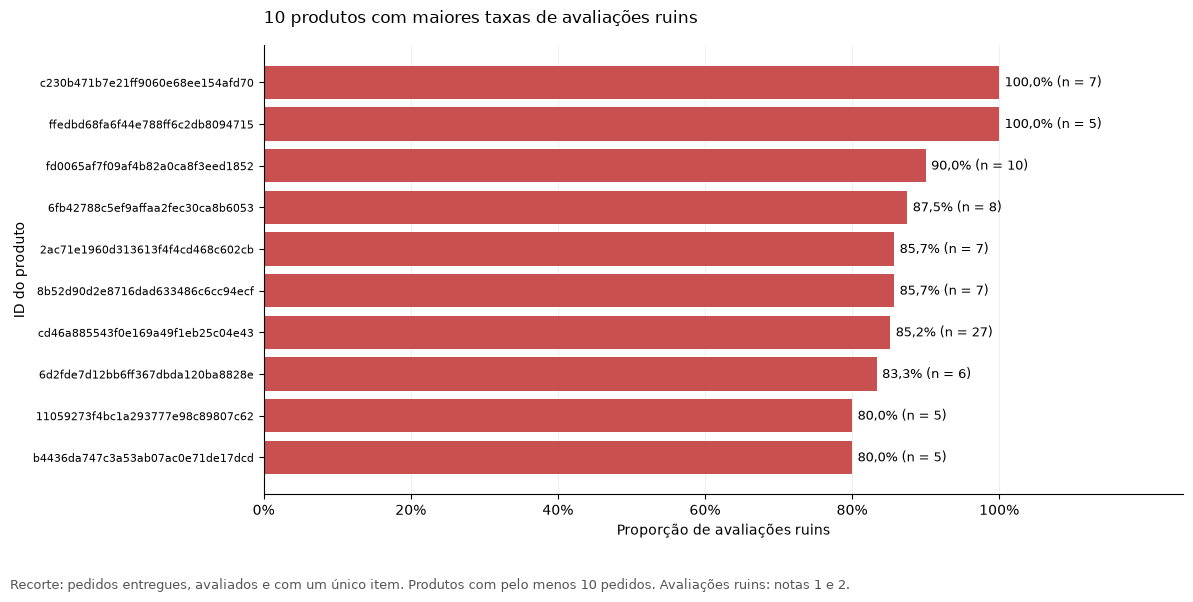

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))

# Desenha somente a taxa como comprimento da barra.
# A quantidade de pedidos será apresentada como texto.
barras = ax.barh(
    df_grafico_produtos.index,
    df_grafico_produtos['Reviews_ruins'],
    color='#C95050'
)

# Coloca o primeiro produto do ranking no topo.
ax.invert_yaxis()

ax.set_title(
    '10 produtos com maiores taxas de avaliações ruins',
    loc='left',
    pad=16
)

ax.set_xlabel('Proporção de avaliações ruins')
ax.set_ylabel('ID do produto')

# Os valores estão entre 0 e 1.
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

# Reserva espaço para os textos ao lado das barras.
ax.set_xlim(0, 1.25)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

# Monta um rótulo com a taxa e a quantidade de pedidos.
rotulos = [
    f'{taxa:.1%} (n = {int(quantidade)})'.replace('.', ',')
    for taxa, quantidade in zip(
        df_grafico_produtos['Reviews_ruins'],
        df_grafico_produtos['Quantidade']
    )
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=4,
    fontsize=9
)

ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='y', labelsize=8)

fig.text(
    0.01,
    0.01,
    'Recorte: pedidos entregues, avaliados e com um único item. '
    'Produtos com pelo menos 10 pedidos. Avaliações ruins: notas 1 e 2.',
    fontsize=9,
    color='#555555'
)

fig.tight_layout(rect=[0, 0.07, 1, 1])
registrar_grafico(fig, '03_produtos_top10_avaliacoes.png')
plt.show()
plt.close(fig)


In [15]:
from pathlib import Path

# Evita interpretar os símbolos de R$ como fórmulas matemáticas.
plt.rcParams['text.parse_math'] = False

# Reutiliza os caminhos definidos na leitura das bases.
# Reutiliza a raiz identificada na célula de leitura dos dados.
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'


# Uma função evita repetir a mesma formatação em todos os gráficos.
def finalizar_grafico(figura, nome_arquivo, nota):
    figura.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    figura.tight_layout(rect=[0, 0.08, 1, 1])
    # Salva antes de mostrar e fechar a figura.
    registrar_grafico(figura, PASTA_GRAFICOS / nome_arquivo, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(figura)


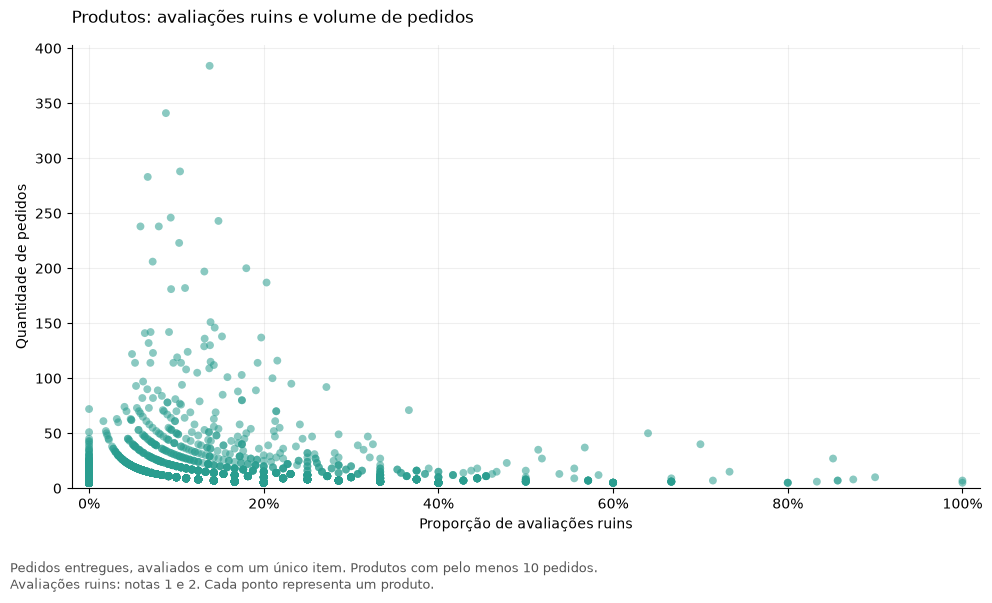

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

# Usa todos os produtos elegíveis, e não somente o top 10.
ax.scatter(
    df_ranking_produtos['pct_reviews_ruins'],
    df_ranking_produtos['quantidade_pedidos'],
    color='#2A9D8F', alpha=0.55, s=32, edgecolors='none'
)
ax.set_title('Produtos: avaliações ruins e volume de pedidos', loc='left', pad=16)
ax.set_xlabel('Proporção de avaliações ruins')
ax.set_ylabel('Quantidade de pedidos')
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(-0.02, 1.02)  # Margem para não cortar pontos em 0% ou 100%.
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
finalizar_grafico(
    fig, '03_produtos_dispersao.png',
    'Pedidos entregues, avaliados e com um único item. Produtos com pelo menos 10 pedidos.\n'
    'Avaliações ruins: notas 1 e 2. Cada ponto representa um produto.'
)


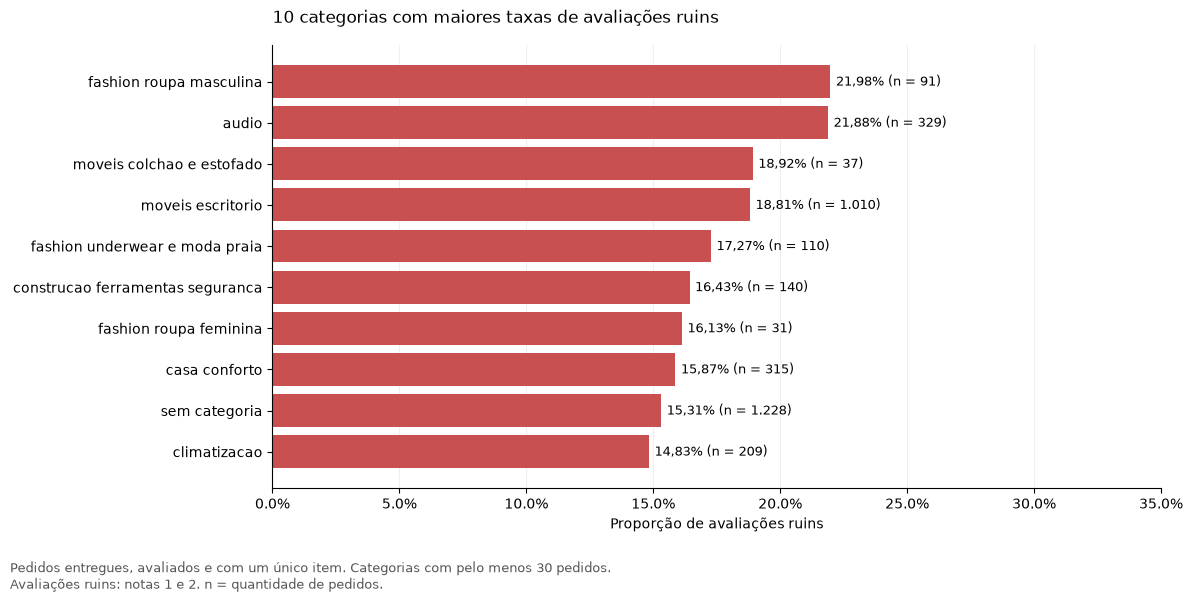

In [17]:
df_grafico_categorias = df_ranking_categorias.head(10).copy()
fig, ax = plt.subplots(figsize=(12, 6))
barras = ax.barh(
    df_grafico_categorias['categoria_analise'].str.replace('_', ' '),
    df_grafico_categorias['pct_reviews_ruins'], color='#C95050'
)
ax.invert_yaxis()  # Primeira posição do ranking no topo.
rotulos = [
    f"{taxa:.2%}".replace('.', ',') + f" (n = {int(n):,})".replace(',', '.')
    for taxa, n in zip(df_grafico_categorias['pct_reviews_ruins'],
                       df_grafico_categorias['quantidade_pedidos'])
]
ax.bar_label(barras, labels=rotulos, padding=4, fontsize=9)
ax.set_title('10 categorias com maiores taxas de avaliações ruins', loc='left', pad=16)
ax.set_xlabel('Proporção de avaliações ruins')
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(0, 0.35)  # Começa em zero e deixa espaço para os rótulos.
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
finalizar_grafico(
    fig, '03_categorias_top10.png',
    'Pedidos entregues, avaliados e com um único item. Categorias com pelo menos 30 pedidos.\n'
    'Avaliações ruins: notas 1 e 2. n = quantidade de pedidos.'
)


In [18]:
def criar_grafico_faixas(resumo, caracteristica, nome_arquivo):
    # A tabela original pode estar em ordem de ocorrência dos pedidos.
    # Ordenar pelo menor valor observado coloca as faixas na ordem numérica.
    dados = resumo.sort_values('valor_minimo').copy()
    fig, ax = plt.subplots(figsize=(11, 5.5))
    barras = ax.barh(
        dados['faixa'].astype(str), dados['pct_reviews_ruins'], color='#C95050'
    )
    ax.invert_yaxis()  # Menor faixa no topo.
    rotulos = [
        f"{taxa:.2%}".replace('.', ',') + f" (n = {int(n):,})".replace(',', '.')
        for taxa, n in zip(dados['pct_reviews_ruins'], dados['quantidade_pedidos'])
    ]
    ax.bar_label(barras, labels=rotulos, padding=4, fontsize=9)
    ax.set_title(f'Avaliações ruins por faixa de {caracteristica}', loc='left', pad=16)
    ax.set_xlabel('Proporção de avaliações ruins')
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_xlim(0, max(0.20, float(dados['pct_reviews_ruins'].max()) * 1.4))  # Mesma escala, de 0% a 20%, nos três gráficos.
    ax.set_xticks([0, 0.05, 0.10, 0.15, 0.20])
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    finalizar_grafico(
        fig, nome_arquivo,
        'Pedidos entregues, avaliados, com um único item e informação disponível para a característica.\n'
        'Faixas baseadas em quintis com limites arredondados. Avaliações ruins: notas 1 e 2. n = pedidos.'
    )


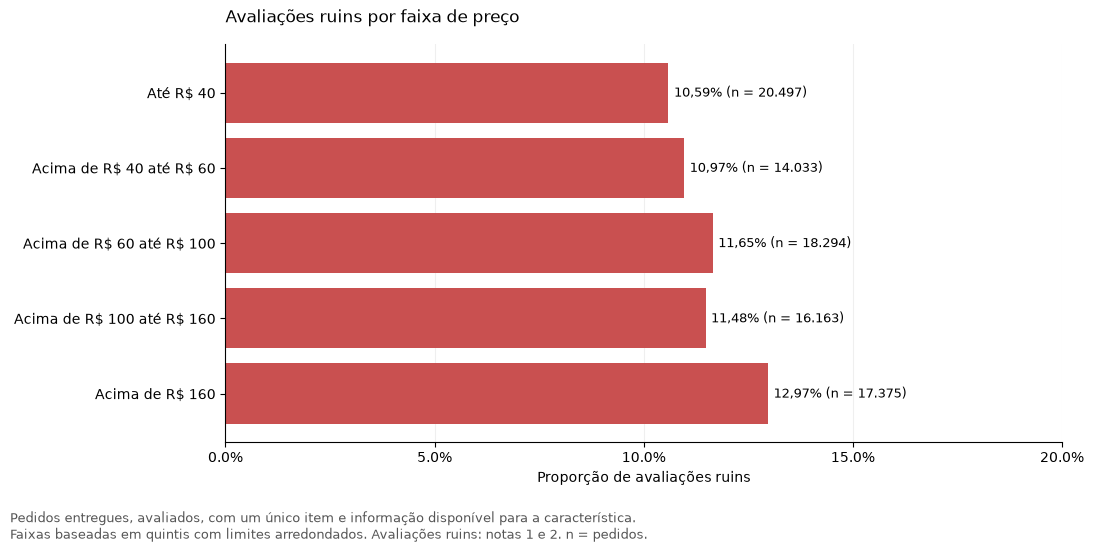

In [19]:
# Reutiliza a função de desenho com a tabela de preço.
criar_grafico_faixas(df_faixas_preco, 'preço', '03_produtos_faixas_preco.png')


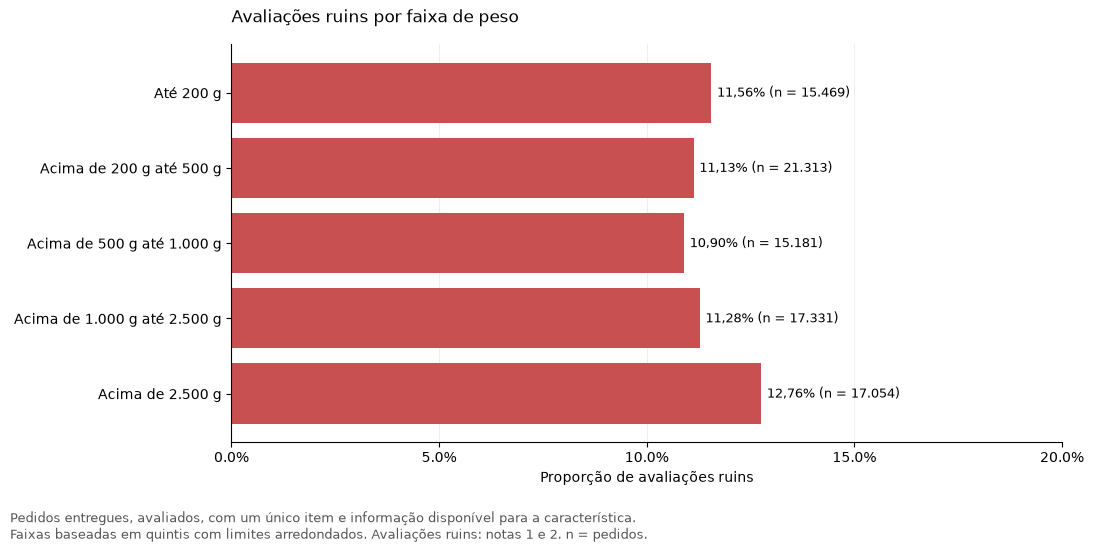

In [20]:
# Reutiliza a função de desenho com a tabela de peso.
criar_grafico_faixas(df_faixas_peso, 'peso', '03_produtos_faixas_peso.png')


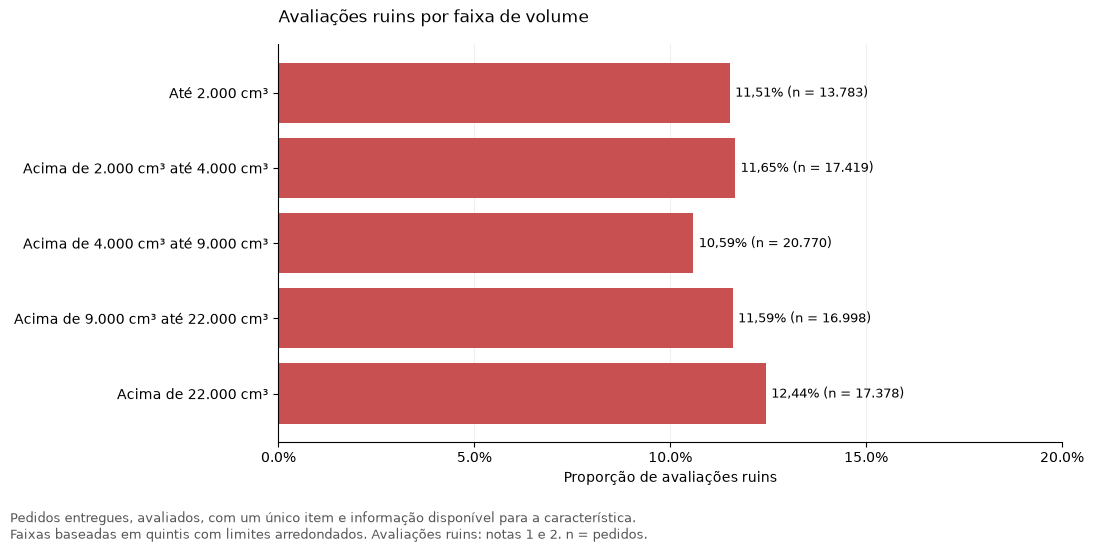

In [21]:
# Reutiliza a função de desenho com a tabela de volume.
criar_grafico_faixas(df_faixas_volume, 'volume', '03_produtos_faixas_volume.png')


## Exportações

Salva as tabelas em Parquet e CSV e os gráficos em PNG.

In [22]:
PASTA_PARQUET = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'parquet'
PASTA_CSV = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'csv'
for pasta in (PASTA_PARQUET, PASTA_CSV, PASTA_GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)

tabelas_exportar = {
    '03_ranking_produtos': df_ranking_produtos,
    '03_ranking_categorias': df_ranking_categorias,
    '03_faixas_preco': df_faixas_preco,
    '03_faixas_peso': df_faixas_peso,
    '03_faixas_volume': df_faixas_volume,
}
for nome, original in tabelas_exportar.items():
    tabela = original.reset_index(drop=True).convert_dtypes()
    caminho = PASTA_PARQUET / f'{nome}.parquet'
    tabela.to_parquet(caminho, index=False)
    pd.testing.assert_frame_equal(tabela, pd.read_parquet(caminho), check_exact=True)
    tabela.to_csv(
        PASTA_CSV / f'{nome}.csv', index=False,
        sep=';', decimal=',', encoding='utf-8-sig'
    )
    print(f'Tabela exportada em Parquet e CSV: {nome} ({len(tabela)} linhas)')

for nome, conteudo in graficos_exportar.items():
    (PASTA_GRAFICOS / nome).write_bytes(conteudo)
    print(f'Gráfico exportado: {nome}')


Tabela exportada em Parquet e CSV: 03_ranking_produtos (3501 linhas)
Tabela exportada em Parquet e CSV: 03_ranking_categorias (67 linhas)
Tabela exportada em Parquet e CSV: 03_faixas_preco (5 linhas)
Tabela exportada em Parquet e CSV: 03_faixas_peso (5 linhas)
Tabela exportada em Parquet e CSV: 03_faixas_volume (5 linhas)
Gráfico exportado: 03_produtos_top10_avaliacoes.png
Gráfico exportado: 03_produtos_dispersao.png
Gráfico exportado: 03_categorias_top10.png
Gráfico exportado: 03_produtos_faixas_preco.png
Gráfico exportado: 03_produtos_faixas_peso.png
Gráfico exportado: 03_produtos_faixas_volume.png
